# Flight Price Prediction — EDA

In [25]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [26]:

# Works whether Jupyter is launched from project root or notebooks/
_cwd = Path().resolve()
ROOT = _cwd if (_cwd / "data").exists() else _cwd.parent
DATA = ROOT / "data"

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")

print("train:", train.shape)
print("test: ", test.shape)
train.head()

train: (18076, 12)
test:  (4520, 11)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


In [27]:
# 1. Basic Inspection
print(train.dtypes)
print("\nNull values:\n", train.isnull().sum())
print("\nDuplicates:", train.duplicated().sum())
train.describe()

id                    int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
flight_class         object
duration            float64
days_left             int64
price                 int64
dtype: object

Null values:
 id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
price               0
dtype: int64

Duplicates: 0


,id,duration,days_left,price
count,18076.000000,18076.000000,18076.000000,18076.000000
mean,11308.626189,2.746853,20.520912,280.264550
std,6526.337957,2.947519,12.094984,221.965133
min,0.000000,0.870000,1.000000,0.000000
25%,5668.750000,1.470000,10.000000,157.000000
50%,11329.500000,1.630000,20.000000,234.000000
75%,16949.500000,2.000000,31.000000,336.000000
max,22595.000000,28.650000,44.000000,8996.000000


In [28]:
# 1b. Data cleaning — remove rows that are not real market prices
zeros_mask = train['price'] <= 0
sae_mask   = train['airline'] == 'Southern_Airways_Express'

print(f"price <= 0 rows ({zeros_mask.sum()}):")
print(train[zeros_mask][['airline', 'flight_class', 'stops', 'price']].to_string())

print(f"\nSouthern_Airways_Express rows: {sae_mask.sum()}")

train = train[~zeros_mask & ~sae_mask].reset_index(drop=True)
print(f"\nTraining rows after cleaning: {len(train)}")
print(f"log1p(price) skew after cleaning: {np.log1p(train['price']).skew():.3f}")

price <= 0 rows (25):
               airline flight_class stops  price
346          Southwest      Economy   one      0
934          Southwest      Economy   one      0
1352         Southwest      Economy   one      0
2762         Southwest      Economy   one      0
3101         Southwest      Economy   one      0
4350         Southwest      Economy   one      0
5386         Southwest      Economy   one      0
5600         Southwest      Economy   one      0
5991   Alaska_Airlines      Economy   one      0
6642         Southwest      Economy   one      0
7640         Southwest      Economy   one      0
7852         Southwest      Economy   one      0
8252         Southwest      Economy   one      0
9025         Southwest      Economy   one      0
10054        Southwest      Economy   one      0
12140        Southwest      Economy   one      0
12411        Southwest      Economy   one      0
13347  Alaska_Airlines     Business   one      0
13615        Southwest      Economy   one      

In [29]:
import copy
from matplotlib.path import Path

def _path_deepcopy(self, memo=None):
    p = copy.copy(self)                      # shallow copy avoids the super() recursion
    p._vertices = self._vertices.copy()
    if self._codes is not None:
        p._codes = self._codes.copy()
    p._readonly = False
    return p

Path.__deepcopy__ = _path_deepcopy

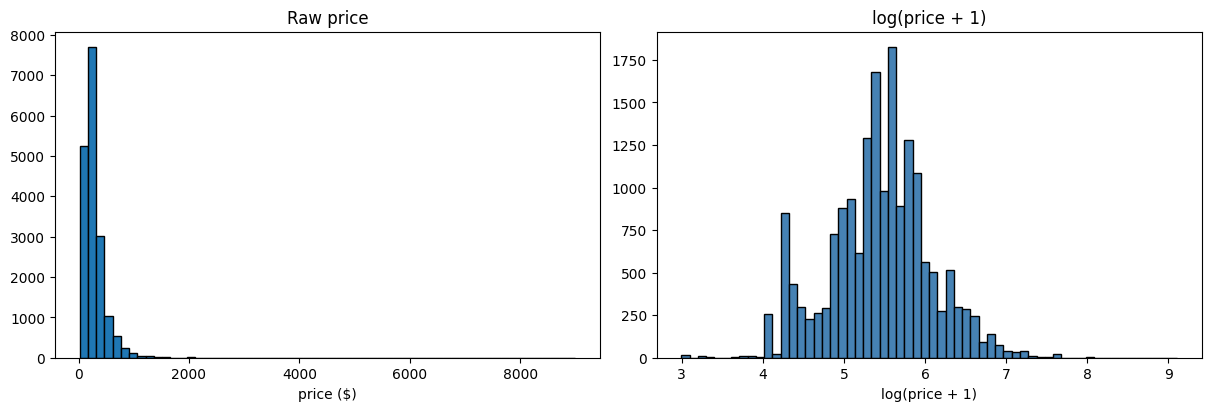

Skew — raw   : 7.087
Skew — log1p : -0.028


In [30]:
# 2. Target variable — raw distribution vs log transform
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')

ax1.hist(train['price'].to_numpy(), bins=60, edgecolor='black')
ax1.set_title('Raw price')
ax1.set_xlabel('price ($)')

ax2.hist(np.log1p(train['price'].to_numpy()), bins=60, edgecolor='black', color='steelblue')
ax2.set_title('log(price + 1)')
ax2.set_xlabel('log(price + 1)')

plt.show()

print(f"Skew — raw   : {train['price'].skew():.3f}")
print(f"Skew — log1p : {np.log1p(train['price']).skew():.3f}")

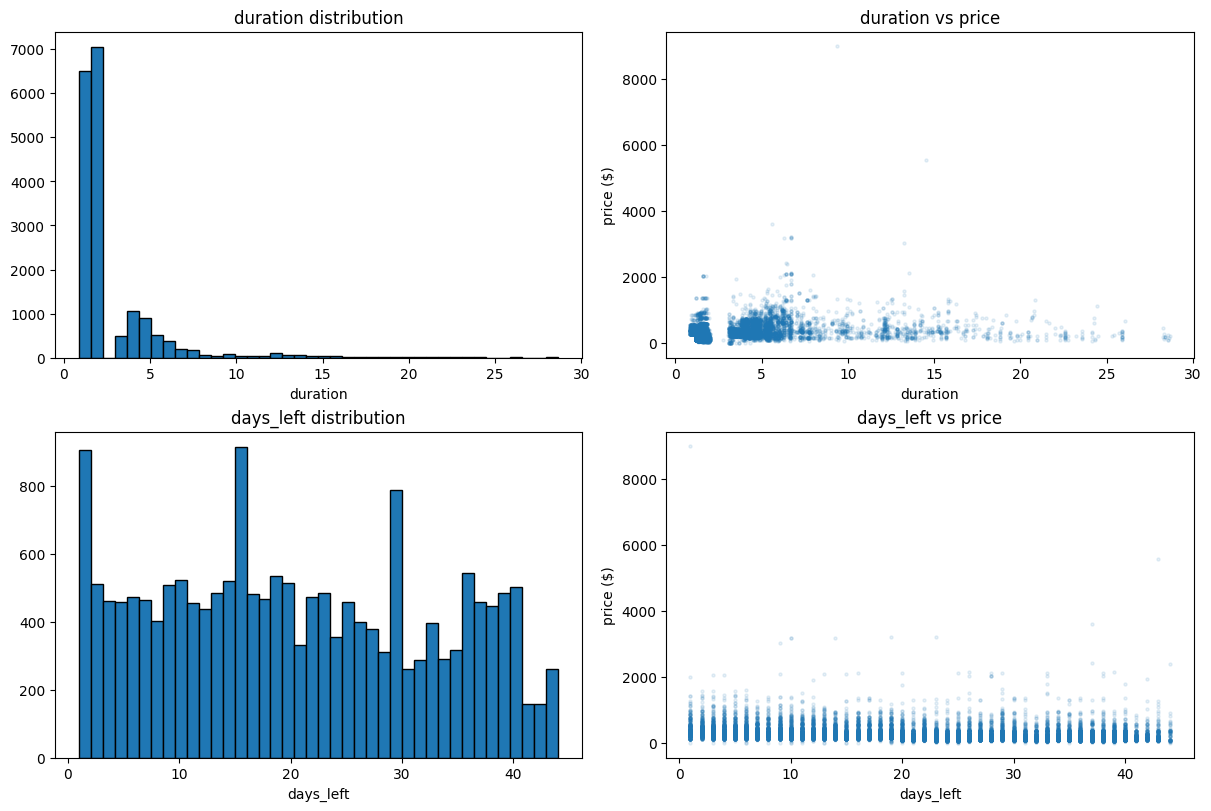

In [21]:
# 3. Numeric features — distribution and scatter vs price
numeric_cols = ['duration', 'days_left']

fig, axes = plt.subplots(len(numeric_cols), 2, figsize=(12, 4 * len(numeric_cols)), layout='constrained')
for i, col in enumerate(numeric_cols):
    axes[i, 0].hist(train[col].to_numpy(), bins=40, edgecolor='black')
    axes[i, 0].set_title(f'{col} distribution')
    axes[i, 0].set_xlabel(col)

    axes[i, 1].scatter(train[col].to_numpy(), train['price'].to_numpy(), alpha=0.1, s=5)
    axes[i, 1].set_xlabel(col)
    axes[i, 1].set_ylabel('price ($)')
    axes[i, 1].set_title(f'{col} vs price')

plt.show()

In [31]:
# 3b. days_left non-linearity — price plateaus in the final week
bins   = [0, 3, 7, 14, 21, 30, 44]
labels = ['0–3', '4–7', '8–14', '15–21', '22–30', '31–44']
bucket = pd.cut(train['days_left'], bins=bins, labels=labels, include_lowest=True)

print("Median price by days_left bucket:")
print(train.groupby(bucket, observed=True)['price'].median().to_string())
print("\n→ Prices are flat for days_left <= 7 then fall steadily.")
print("  Adding a binary last_week flag (days_left <= 7) is cheap and easy to justify.")

Median price by days_left bucket:
days_left
0–3      315.0
4–7      305.0
8–14     262.0
15–21    234.0
22–30    199.0
31–44    179.0

→ Prices are flat for days_left <= 7 then fall steadily.
  Adding a binary last_week flag (days_left <= 7) is cheap and easy to justify.


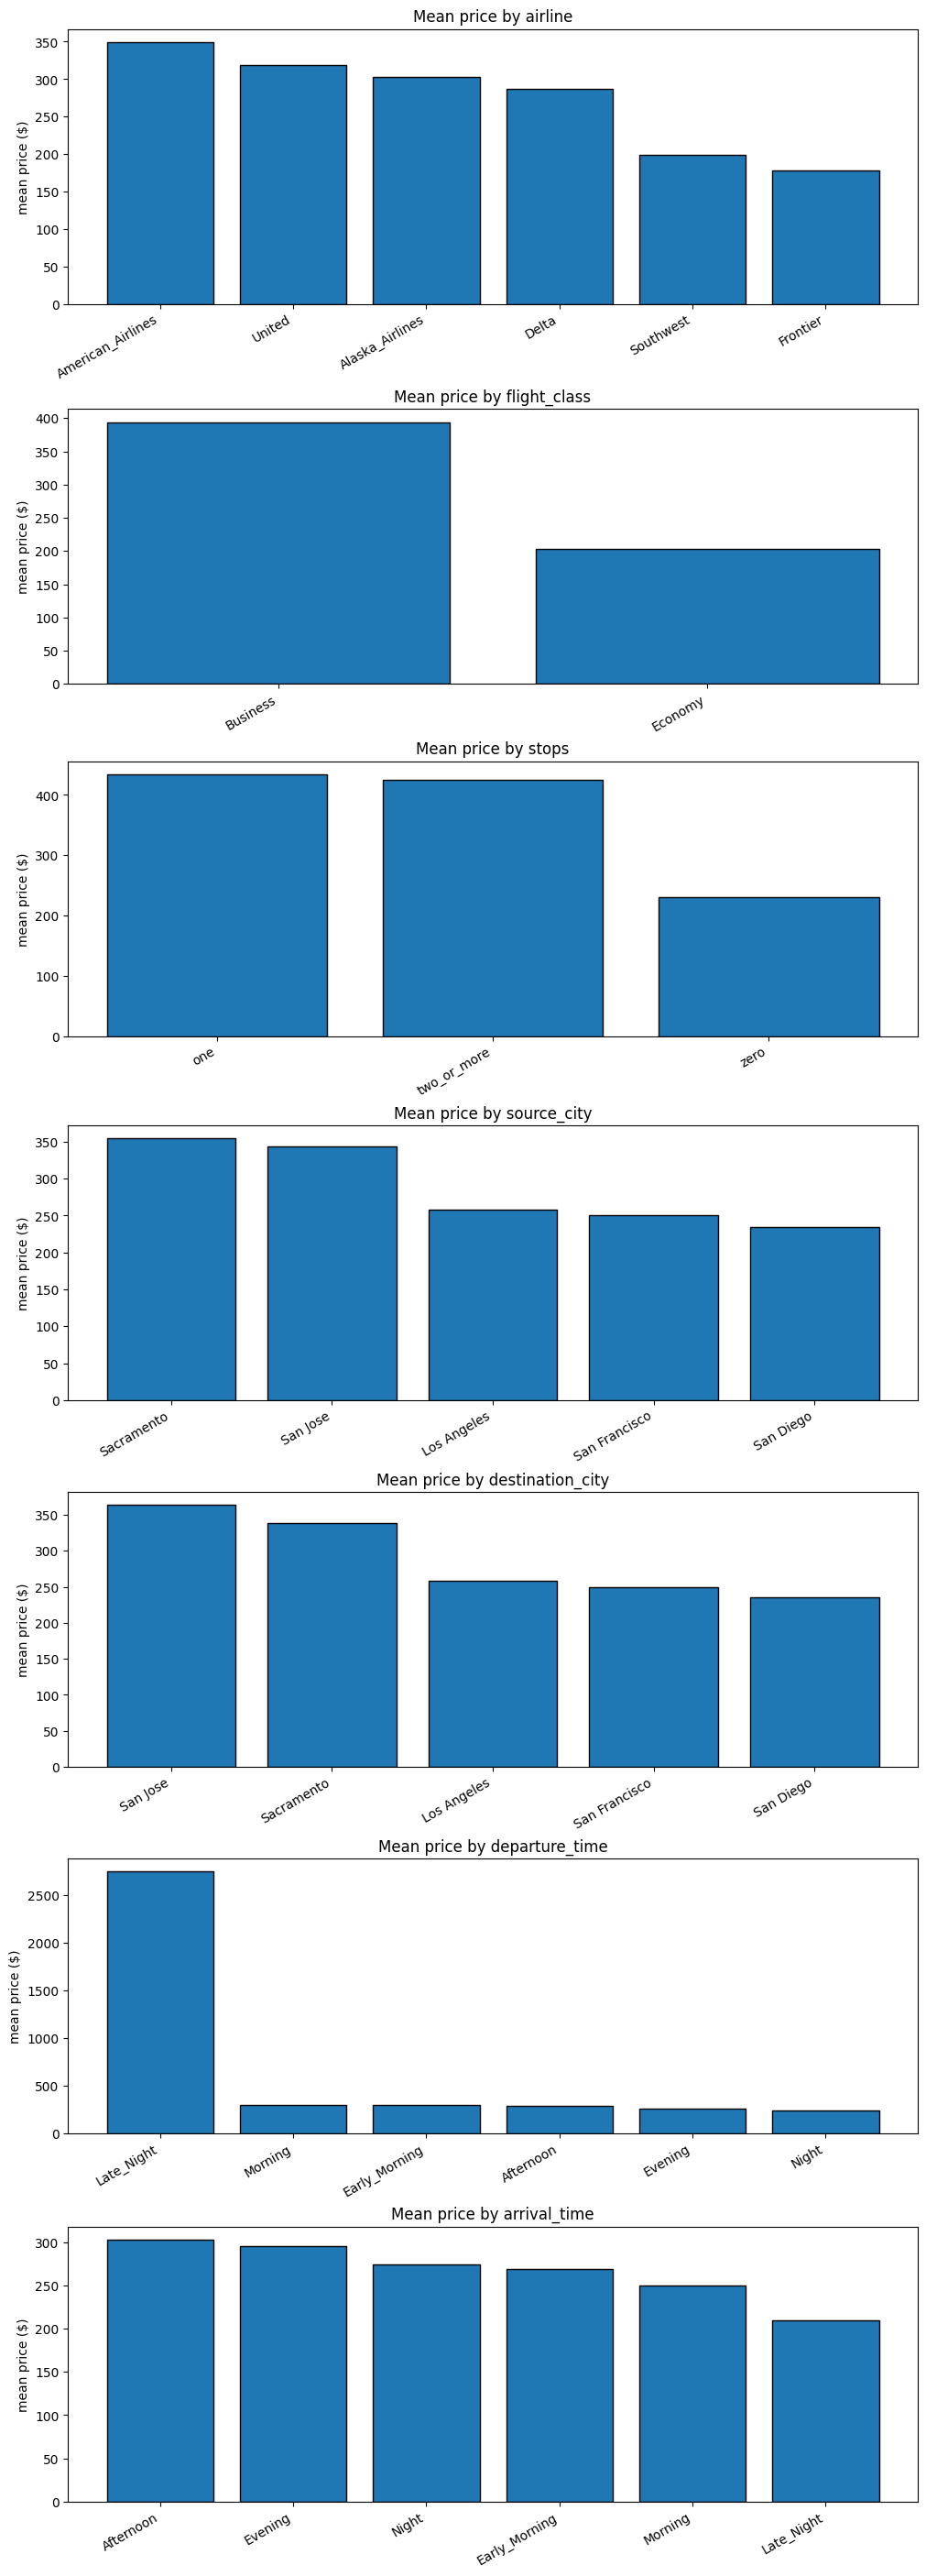

In [32]:
# 4. Categorical features — mean price per category
cat_cols = [
    'airline', 'flight_class', 'stops',
    'source_city', 'destination_city',
    'departure_time', 'arrival_time',
]

fig, axes = plt.subplots(len(cat_cols), 1, figsize=(10, 4 * len(cat_cols)), layout='constrained')
for ax, col in zip(axes, cat_cols):
    mean_price = train.groupby(col)['price'].mean().sort_values(ascending=False)
    ax.bar(range(len(mean_price)), mean_price.to_numpy(), edgecolor='black')
    ax.set_xticks(range(len(mean_price)))
    ax.set_xticklabels(mean_price.index, rotation=30, ha='right')
    ax.set_title(f'Mean price by {col}')
    ax.set_ylabel('mean price ($)')

plt.show()

In [33]:
# 5. The `flight` column — cardinality check (decide whether to keep or drop)
print(f"Unique flight codes : {train['flight'].nunique()}  ({train['flight'].nunique() / len(train) * 100:.1f}% of rows)")
print(f"Unique airlines     : {train['airline'].nunique()}")
print("\nTop 10 most-common flight codes:")
print(train['flight'].value_counts().head(10))

Unique flight codes : 1121  (6.2% of rows)
Unique airlines     : 6

Top 10 most-common flight codes:
flight
AA 6279    183
DL 3716    156
DL 3883    149
AA 1358    144
DL 4087    141
DL 3755    136
DL 3712    130
AA 6278    130
AA 6277    129
DL 3700    125
Name: count, dtype: int64


In [34]:
# 5b. Preprocessing validation — confirm encodings are exhaustive and train/test align

stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
time_map  = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2,
             'Evening': 3, 'Night': 4, 'Late_Night': 5}

print("=== Ordinal map coverage ===")
for col, mapping in [('stops', stops_map), ('departure_time', time_map), ('arrival_time', time_map)]:
    unseen_train = set(train[col].unique()) - set(mapping)
    unseen_test  = set(test[col].unique())  - set(mapping)
    print(f"  {col}: unmapped in train={unseen_train or '∅'}, test={unseen_test or '∅'}")

print("\n=== OHE column train/test alignment ===")
ohe_cols = ['airline', 'source_city', 'destination_city']
for col in ohe_cols:
    only_in_test = set(test[col].unique()) - set(train[col].unique())
    print(f"  {col}: in test but not train → {only_in_test or '∅'}")

print("\n=== Rare OHE categories (< 10 rows in train) ===")
for col in ohe_cols:
    rare = train[col].value_counts()
    rare = rare[rare < 10]
    print(f"  {col}: {rare.to_dict() or '∅'}")

print("\n=== Duration outliers (> 10 hrs, suspicious for domestic) ===")
long_flights = train[train['duration'] > 10][['airline', 'source_city', 'destination_city', 'stops', 'duration']]
print(f"  {len(long_flights)} rows")
if len(long_flights):
    print(long_flights.to_string())

=== Ordinal map coverage ===
  stops: unmapped in train=∅, test=∅
  departure_time: unmapped in train=∅, test=∅
  arrival_time: unmapped in train=∅, test=∅

=== OHE column train/test alignment ===
  airline: in test but not train → ∅
  source_city: in test but not train → ∅
  destination_city: in test but not train → ∅

=== Rare OHE categories (< 10 rows in train) ===
  airline: ∅
  source_city: ∅
  destination_city: ∅

=== Duration outliers (> 10 hrs, suspicious for domestic) ===
  618 rows
                 airline    source_city destination_city        stops  duration
76                United     Sacramento         San Jose          one     14.88
104      Alaska_Airlines      San Diego      Los Angeles          one     10.75
112               United  San Francisco       Sacramento  two_or_more     13.72
245      Alaska_Airlines     Sacramento         San Jose          one     15.35
254    American_Airlines     Sacramento    San Francisco          one     13.60
256             Frontie

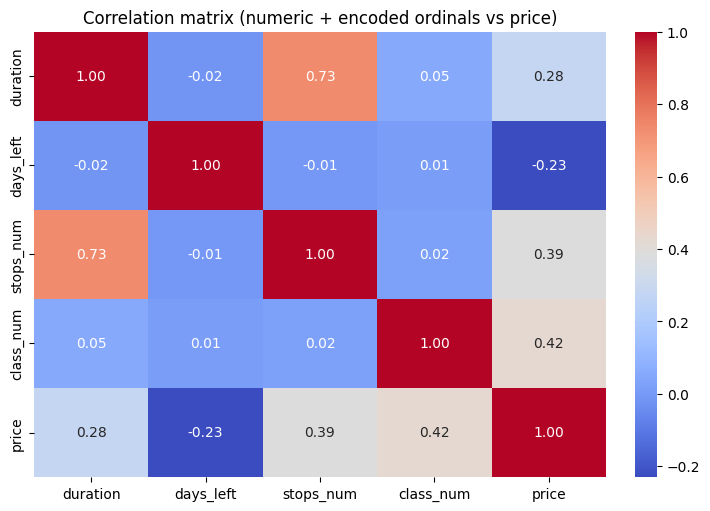

Note: class_num r≈0.42 reflects domestic first-class (~1.7× premium),
not long-haul business class (~7× premium seen in other datasets).


In [35]:
# 6. Correlation (encode ordinals to examine linear relationships with price)
tmp = train.assign(
    stops_num=train['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2}),
    class_num=(train['flight_class'] == 'Business').astype(int),
)

corr = tmp[['duration', 'days_left', 'stops_num', 'class_num', 'price']].corr()

fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlation matrix (numeric + encoded ordinals vs price)')
plt.show()

print("Note: class_num r≈0.42 reflects domestic first-class (~1.7× premium),")
print("not long-haul business class (~7× premium seen in other datasets).")

## 7. Decisions Summary

| Feature / Decision | Choice | Reason |
|---|---|---|
| Drop `id` | Yes | Row identifier only — no predictive signal |
| Drop `flight` | Yes | 1,123 unique codes; flight prefix maps 1-to-1 onto airline so it adds no information; OHE would also inflate feature space |
| Drop `price <= 0` rows | Yes (25 rows) | Scraping artifact / companion fare — not real market prices; these 25 rows shift log1p(price) skew from −0.03 to −0.74 |
| Drop `Southern_Airways_Express` row | Yes (1 row) | Single training example with zero test presence — a one-hot column learned from one row |
| `stops` encoding | Ordinal (zero=0, one=1, two_or_more=2) | Naturally ordered; a single integer preserves ordering without extra columns |
| `flight_class` encoding | Binary (Economy=0, Business=1) | Two values with clear ordinal meaning |
| `departure_time` / `arrival_time` | Ordinal (Early_Morning=0 → Late_Night=5) | Time-of-day has a natural order |
| `airline`, `source_city`, `destination_city` | One-hot encode | No natural order; small enough cardinality for OHE |
| `last_week` flag | Add binary feature: `days_left <= 7` | Prices plateau in the final week then fall steadily — a linear model won't capture this kink on its own |
| Target `price` | log1p transform | Raw price is right-skewed; log makes the distribution nearly symmetric (skew ≈ −0.03 after cleaning) |
| Feature scaling | StandardScaler on all numeric inputs | Required so Ridge / Lasso / ElasticNet penalty applies fairly across features of different magnitudes |
| Regularization strategy | Ridge → Lasso → ElasticNet | Ridge as baseline; Lasso for implicit feature selection via sparsity; ElasticNet as compromise |
| `class_num` r ≈ 0.42 | Expected — keep encoding | US domestic first-class is ~1.7× Economy median, not 7× as in long-haul datasets; the encoding is correct |